In [21]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, recall_score, f1_score, precision_score, confusion_matrix, roc_auc_score,classification_report
import pandas as pd
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Dataset Exploration:

(569, 30)
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']
['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter

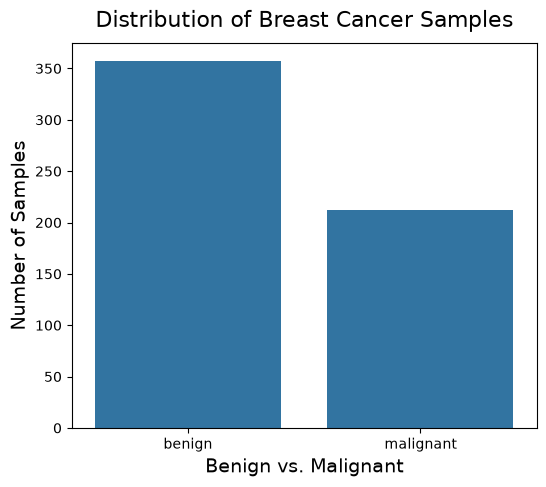

In [22]:
data = load_breast_cancer(as_frame= True)
X = data.data
y = (data.target == 0).astype(int)

print(X.shape)
print(X.columns.tolist())
print(data.feature_names)
print(y.value_counts())
print(data.target)
print(data.target_names)
percentages = y.value_counts(normalize=True) * 100
print(percentages)
print("Total missing values in X:", X.isnull().sum().sum())
print("Total missing values in y:", y.isnull().sum())

class_names = y.map({0: 'benign', 1: 'malignant'})
counts = class_names.value_counts()


plt.figure(figsize=(6,5))
sns.barplot(x= counts.index, y= counts.values)
plt.ylabel('Number of Samples', fontsize= 14)
plt.xlabel('Benign vs. Malignant', fontsize= 14)
plt.title('Distribution of Breast Cancer Samples', y=1.02, fontsize=16)
plt.show()


## Answers to Questions:

1.) The current split is 63%(357/569) towards benign and 37%(212/569) towards malignant. This split indicates that the split is moderately imbalanced that the accuracy alone could hide the performance on malignant cases.
2.) The class distribution should be examined before selecting the evaluation metric, because if the class distribution is imbalanced, like it currently is we would need a metric that individually looks at each class, like recall which would ask whether the model finds the cancer or not.
3.) Malignant is the positive class in this homework, because the objective is to detect cancerous tumors from their measurements. the recall is measured from the positive class, so recall shows how many malignant tumors the model catches.

In [23]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50,
    random_state=42, stratify=y_temp
)

## Training Validation and Test Splitting 

## Answers to the Questions:

1.) The purpose of the training split is so that the model is able to learn from the data and establish a pattern from the tumors and their measurements and their labels and for the pattern to work on tumors it has never seen.
2.)The validation set is similar to test set, though it serves the purpose of assistance in deciding the best model for finding which model creates the best generalization and the best model is used against the test set.
3.)The test set is used to measure the model's abilities on making predictions against data that the model hasn't seen before and this helps us decide whether the model properly generalizes on this new data or just memorizing the given dataset.
4.)Stratification ensures that the malignant and benign ratio are about the same in every pile.
5.)If one subset had a very different class distribution then this could cause the overall class to be skewed, which could misrepresent performance.
6.)The test set should remain unused, as exposing the model to all of the data at once could present the possibility of the model memorizing the data set, without establishing a proper generalization between the current data and any new data presented.
7.) The random_state ensures that random steps are repeatable.


In [24]:

cv = StratifiedKFold(
n_splits=5,
shuffle=True,
random_state=42
)
for fold_number, (train_index, fold_index) in enumerate(
cv.split(X_train, y_train), start=1
):
    y_fold_train = y_train.iloc[train_index]
    y_fold_val = y_train.iloc[fold_index]
    print(f"Fold {fold_number}")
    print("Training size:", len(y_fold_train))
    print("Validation size:", len(y_fold_val))
    print(y_fold_val.value_counts(normalize=True))

cv_model = RandomForestClassifier(
n_estimators=100,
max_depth=5,
random_state=42,
n_jobs=-1
)
scoring = {
"accuracy": "accuracy",
"precision": "precision",
"recall": "recall",
"f1": "f1",
"roc_auc": "roc_auc"
}
cv_results = cross_validate(
cv_model, X_train, y_train,
cv=cv, scoring=scoring,
return_train_score=False
)

cv_scores = pd.DataFrame({
    "Fold": range(1, 6),
    "Accuracy": cv_results["test_accuracy"],
    "Precision": cv_results["test_precision"],
    "Recall": cv_results["test_recall"],
    "F1": cv_results["test_f1"],
    "ROC-AUC": cv_results["test_roc_auc"]
})

display(cv_scores)
display(cv_scores.drop(columns="Fold").agg(["mean", "std"]))

Fold 1
Training size: 272
Validation size: 69
target
0    0.623188
1    0.376812
Name: proportion, dtype: float64
Fold 2
Training size: 273
Validation size: 68
target
0    0.617647
1    0.382353
Name: proportion, dtype: float64
Fold 3
Training size: 273
Validation size: 68
target
0    0.632353
1    0.367647
Name: proportion, dtype: float64
Fold 4
Training size: 273
Validation size: 68
target
0    0.632353
1    0.367647
Name: proportion, dtype: float64
Fold 5
Training size: 273
Validation size: 68
target
0    0.632353
1    0.367647
Name: proportion, dtype: float64


,Fold,Accuracy,Precision,Recall,F1,ROC-AUC
0,1,0.971014,0.961538,0.961538,0.961538,0.999106
1,2,0.955882,1.000000,0.884615,0.938776,0.990842
2,3,0.970588,0.925926,1.000000,0.961538,0.998140
3,4,0.897059,0.875000,0.840000,0.857143,0.975814
4,5,0.955882,0.958333,0.920000,0.938776,0.985116


,Accuracy,Precision,Recall,F1,ROC-AUC
mean,0.950085,0.944160,0.921231,0.931554,0.989804
std,0.030567,0.046735,0.062789,0.043126,0.009680


## Answers to questions: 

1.)Stratified cross-validation is better because folds keep about the same malignant to benign mix as the full training set. This ensures that no fold has too few malignant tumors to score fairly, and the five scores are comparable to each other.
2.)Each of the five folds trains a new model on its four training pieces, so the model is fit five times during the cross-validation.
3.)Since each fold represents an iteration, the fold is fit on 80% of the training data and it is validated on the remaining 20% of the data.
4.)Recall has the largest deviation by far at 0.0839 with a mean of 0.929.
5.)The spread tells us whether the model's ability to catch malignant tumors stays steady across different groups of tumors. A smaller spread means it's consistent, while a large spread means its recall depends on which tumors happened to land in each fold.
6.)The mean shows the model's average performance across all folds, while the std. deviation shows how consistent that performance is. Reporting both helps determine whether a model performs well consistently rather than only performing well on certain splits of the data.
8.)No, cross-validation scores helps estimate which model is best using training data. The untouched test set gives the final unbiased evaluation.

## Create a Baseline Classifier

In [25]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
y_baseline = baseline.predict(X_val)

print(accuracy_score(y_val, y_baseline))
print(recall_score(y_val, y_baseline))
print(f1_score(y_val, y_baseline))
print(precision_score(y_val, y_baseline))
print(confusion_matrix(y_val, y_baseline))

0.6228070175438597
0.0
0.0
0.0
[[71  0]
 [43  0]]


c:\Users\bnhen\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


## Answers to questions:
1.) The baseline always predicts benign, because benign is the majority, its malignant recall is 0 means it misses every cancer, which makes it a weak baseline.
2.) Its accuracy might seem reasonable due to benign being the majority class, so predicting every sample as benign still results in many correct predictions.
3.)The recall for malignant is 0 and this is important because the recall for malignant cases does not correctly predict any malignant cases. This is important because all 43 actual malignant cases are missed by the classifier.
4.)Random forest needs to actually identify malignant cases while maintaining good perfomrance.w

In [26]:
model = RandomForestClassifier(
n_estimators=100,
max_depth=None,
random_state=42,
n_jobs=-1
)
model.fit(X_train, y_train)
y_val_pred = model.predict(X_val)
y_val_prob = model.predict_proba(X_val)[:, 1]

## Answers to questions:

1.) A collection of diverse trees is more reliable because the trees can compensate for each other's mistakes. Combining their predictions reduce the impact of one tree making a poor prediction and produces a more stable result.
2.)n_estimators controls the number of decision trees used in the Random Forest
3.)An unrestricted max_depth can contribute to overfitting as max_depth allows the trees to become increasingly more complex and potentially learn patterns specific to the training data rather than patterns that generalize to unseen data.
4.)The purpose of setting random_state is so that the model's random processes are reproducible, allowing us to get the same results each time the code is run.

In [27]:
model_A = RandomForestClassifier(
    n_estimators=50,
    max_depth = 3,
    class_weight=None,
    random_state=42,
    n_jobs=-1
)
model_B = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    class_weight=None,
    random_state=42,
    n_jobs=-1
)
model_C = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    class_weight=None, 
    random_state=42,
    n_jobs=-1
)
model_D = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

modelA_results = cross_validate(
    model_A, X_train, y_train,
    cv=cv, scoring=scoring,
    return_train_score=False
)

modelB_results = cross_validate(
    model_B, X_train, y_train,
    cv=cv, scoring=scoring,
    return_train_score=False
)
modelC_results = cross_validate(
    model_C, X_train, y_train,
    cv=cv, scoring=scoring,
    return_train_score=False
)
modelD_results = cross_validate(
    model_D, X_train, y_train,
    cv=cv, scoring=scoring,
    return_train_score=False
)

mean_rows = []
std_rows = []

result = {
    "A": modelA_results,
    "B": modelB_results,
    "C": modelC_results,
    "D": modelD_results
}

for model_name, model_result in result.items():
    mean_row = {
        "Model": model_name,
        "Mean Accuracy": model_result["test_accuracy"].mean(),
        "Mean Precision": model_result["test_precision"].mean(),
        "Mean Recall": model_result["test_recall"].mean(),
        "Mean F1": model_result["test_f1"].mean(),
        "Mean ROC-AUC": model_result["test_roc_auc"].mean()
    }

    std_row = {
        "Model": model_name,
        "Std Accuracy": model_result["test_accuracy"].std(),
        "Std Precision": model_result["test_precision"].std(),
        "Std Recall": model_result["test_recall"].std(),
        "Std F1": model_result["test_f1"].std(),
        "Std ROC-AUC": model_result["test_roc_auc"].std()
    }
    mean_rows.append(mean_row)
    std_rows.append(std_row)

mean_results = pd.DataFrame(mean_rows)
std_results = pd.DataFrame(std_rows)

display(mean_results)
display(std_results)
    


,Model,Mean Accuracy,Mean Precision,Mean Recall,Mean F1,Mean ROC-AUC
0,A,0.952984,0.951794,0.921231,0.935141,0.984947
1,B,0.950085,0.944160,0.921231,0.931554,0.989804
2,C,0.952984,0.952847,0.921231,0.935268,0.988886
3,D,0.952984,0.938388,0.936923,0.935896,0.989058


,Model,Std Accuracy,Std Precision,Std Recall,Std F1,Std ROC-AUC
0,A,0.025356,0.039571,0.056160,0.036343,0.013368
1,B,0.027340,0.041801,0.056160,0.038573,0.008658
2,C,0.023588,0.043955,0.056160,0.033938,0.008589
3,D,0.023588,0.038340,0.064219,0.034197,0.009957


In [28]:

# Model D selected 

model_D.fit(X_train, y_train)
val_pred = model_D.predict(X_val)
val_prob = model_D.predict_proba(X_val)[:, 1]

print(accuracy_score(y_val, val_pred))
print(recall_score(y_val, val_pred))
print(f1_score(y_val, val_pred))
print(precision_score(y_val, val_pred))
print(confusion_matrix(y_val, val_pred))
print(roc_auc_score(y_val, val_prob))

0.9649122807017544
0.9302325581395349
0.9523809523809523
0.975609756097561
[[70  1]
 [ 3 40]]
0.9970520799213888


In [29]:

X_train_final = pd.concat([X_train, X_val])
y_train_final = pd.concat([y_train, y_val])

final_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

final_model.fit(X_train_final, y_train_final)

y_test_pred = final_model.predict(X_test)
y_test_prob = final_model.predict_proba(X_test)[:, 1]

In [30]:
print("Accuracy:", round(accuracy_score(y_test, y_test_pred), 3))
print("Precision:", round(precision_score(y_test, y_test_pred), 3))
print("Recall:", round(recall_score(y_test, y_test_pred), 3))
print("F1:", round(f1_score(y_test, y_test_pred), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, y_test_prob), 3))

print("Classification Report:")
print(classification_report(y_test, y_test_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

Accuracy: 0.956
Precision: 0.93
Recall: 0.952
F1: 0.941
ROC-AUC: 0.995
Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.96      0.97        72
           1       0.93      0.95      0.94        42

    accuracy                           0.96       114
   macro avg       0.95      0.96      0.95       114
weighted avg       0.96      0.96      0.96       114

Confusion Matrix:
[[69  3]
 [ 2 40]]


## Answers to questions:

1.) There were 40 true positives, 69 true negatives, 3 false positive, and 2 false negative
2.) The model correctly identified 40 malignant samples.
3.) The model missed 2 malignant samples.
4.) False positive means that the model predicted a tumor was malignant when it actually was bengin. There were 4 false positives 
5.) A false negative means that the model predicted a tumor was benign when it actually was malignant. There was 2 false negatives
6.) A false negative is generally more concerting because a malignant tumor is incorrectly classified as benign. This could cause a malignant tumor to be overlooked or even delay additional testing and treatment.
7.) Yes, the test performance is similar to the cross-validation performance. Model D had a mean cross-validation accuracy of approx. 0.956, recall of 0.953, F1-score 0.943, and ROC-AUC of 0.986, while the final results were 0.947 accuracy, 0.952 recall, 0.930 F1-score, and 0.985 ROC-AUC. Since the differences are small the model seems to be perfroming rather consistently on unseen data and generalizing well.
8.) Large differences between cross-validation, validation, and test-performance could indicate that the model does not generalize well to unseen data. For ex. significantly better cross-validation performance than test performance could be a sign that the model is essentially memorizing the dataset rather than it creating learning patterns that generalize to unseen data or the training data did not fully capture the unseen test data.

## Answers to questions:

1.) Accuracy can be misleading when one class appears more than often than another. A model could predict the majority class most of the time and achieve high accuracy while performing poorly at identifying the minority class.
2.) Precision measures how many of the samples predicted as positive were actually positive. Recall measures how many of the actual positive samples the model successfully identified.
3.)The F1-score balances precision and recall into a single measurement. It is useful when both false positives and false negatives are important when evaluating a model.
4.) Recall should be prioritized when missing a positive case would have serious consequences. For ex. in this dataset, recall is important because a false negative would mean classifying a malignant tumor as benign.
5.)Precision should be prioritized when false positives are particularly costly or undesirable. High precision means that when the model predicts a positive case, that prediction is more likely to actually be correct.
6.) A confusion matrix shows how the model's predictions compare with the actual classes. It separates the results into true positives, true negatives, false positives, and false negatives, allowing us to see what types of errors the model makes.
7.)Accuracy measures the percentage of predictions that the model classified correctly at a particular classification threshold. ROC-AUC measures how well the model can distinguish between the positive and negative classes across different classification thresholds.
8.)Yes, two models can have the same accuracy while making different types of mistakes. For ex. one model could have more false positives while another has more false negatives, but they could still have the same total number of correct predictions.
9.)Prediction probabilities are needed because the ROC curve evaluates model performance across different classification thresholds. The probabilities allow the threshold to be changed so that the true-positive rate and false-positive rate can be compared at different points.
10.)The final test set should be evaluated only once so that it remains an unbiased measurement of the model's performance on unseen data. Repeatedly checking the test results and adjusting the model based on them could cause the model-development process to indirectly overfit to the test set.


In [31]:
importance_df = pd.DataFrame({
"Feature": X.columns,
"Importance": final_model.feature_importances_
}).sort_values("Importance", ascending=False)
display(importance_df.head(10))

,Feature,Importance
22,worst perimeter,0.134889
7,mean concave points,0.125215
23,worst area,0.118959
27,worst concave points,0.112456
20,worst radius,0.065169
6,mean concavity,0.063626
2,mean perimeter,0.061214
0,mean radius,0.048549
3,mean area,0.035863
13,area error,0.034462


## Answers to questions:

1.) The three features with the highest importance are worst perimeter, worst area, and mean concave points. Their importance values are approximately 0.146, 0.128, and 0.113, respectively.

2.)A high feature-importance value suggests that the feature played a larger role in the Random Forest's predictions. The model relied more heavily on that feature when making decisions compared with features that had lower importance values.

3.) No, feature importance does not establish causation. It only shows how useful a feature was to the model when making predictions, but it does not prove that the feature directly causes a tumor to be malignant or benign.

4.) Random Forest feature importance can be difficult to interpret when multiple features contain similar or correlated information. Importance values also show how much the model used a feature, but they do not explain whether higher or lower values of that feature increase the likelihood of a particular prediction.

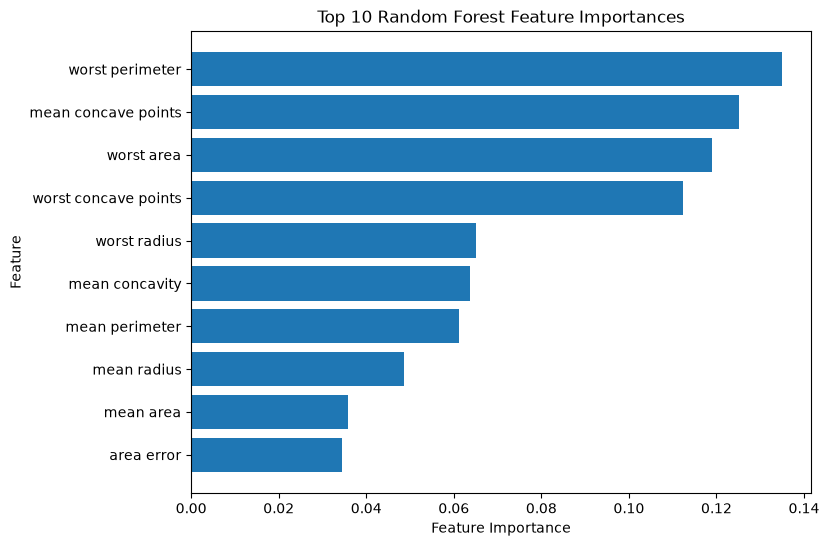

In [32]:
top_10 = importance_df.head(10)

plt.figure(figsize=(8, 6))
plt.barh(top_10["Feature"], top_10["Importance"])
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 10 Random Forest Feature Importances")
plt.gca().invert_yaxis()
plt.show()